# How the WNV–weather dataset is built

This notebook walks through every input to `data/processed/ca_wnv_weather_weekly.csv`:
where each source lives, what its raw data looks like, how `src/` downloads it, what cleaning
happens, and how everything is joined into one row per **California county per MMWR week**.
It ends by rebuilding the dataset from the raw files and checking that the result matches the
saved CSV, then lists the dataset's limitations.

Everything here reads the files already in `data/raw/` and `data/processed/`. A few cells also
fetch a small sample straight from a source, to show its *native* format before the pipeline
touches it. Those cells fall back to a stored example when offline. Set `FETCH_NATIVE = False`
below to skip them.

**Contents**

0. [Setup](#0.-Setup)
1. [Conventions shared by every source](#1.-Conventions-shared-by-every-source)
2. [WNV human cases (CDPH)](#2.-WNV-human-cases-(CDPH))
3. [Temperature and precipitation (NOAA nClimGrid-Daily)](#3.-Temperature-and-precipitation-(NOAA-nClimGrid-Daily))
4. [Humidity and vapor pressure deficit (gridMET)](#4.-Humidity-and-vapor-pressure-deficit-(gridMET))
5. [Drought (US Drought Monitor)](#5.-Drought-(US-Drought-Monitor))
6. [Population (US Census Bureau)](#6.-Population-(US-Census-Bureau))
7. [Joining everything: `build_dataset.py`](#7.-Joining-everything:-build_dataset.py)
8. [The final dataset](#8.-The-final-dataset)
9. [Limitations and open questions](#9.-Limitations-and-open-questions)
10. [Rebuilding from scratch](#10.-Rebuilding-from-scratch)

### The pipeline at a glance

```
 SOURCE (where it lives)                 SCRIPT                    RAW FILE (data/raw/)
 ─────────────────────────────────────   ───────────────────────   ─────────────────────────────────
 CDPH via CHHS Open Data portal      ──▶ download_wnv.py       ──▶ wnv_human_cases.csv
 NOAA nClimGrid-Daily (AWS S3)       ──▶ download_weather.py   ──▶ nclimgrid/YYYYMM_*.csv
                                                                   └▶ nclimgrid_ca_county_daily.csv
 gridMET (THREDDS server, UC Merced) ──▶ download_gridmet.py   ──▶ gridmet/YYYY.csv
   + Census county boundaries                                      └▶ gridmet_ca_county_daily.csv
                                                                   ca_counties.gpkg
 US Drought Monitor API (UNL)        ──▶ download_drought.py   ──▶ usdm/YYYY.csv
                                                                   └▶ usdm_ca_county_weekly.csv
 Census population estimates         ──▶ download_population.py──▶ ca_county_population.csv
                                         (every download is logged to download_log.csv)

                         all raw files ──▶ build_dataset.py ──▶ data/processed/ca_wnv_weather_weekly.csv
                                                            └─▶ data/processed/wnv_unmatched_rows.csv
```

| Source | Native resolution | What the pipeline takes from it |
|---|---|---|
| CDPH WNV cases | county of residence × week reported | `wnv_cases` |
| NOAA nClimGrid-Daily | daily county area averages | `tmax`, `tmin`, `tavg`, `prcp_total`, `n_days` |
| gridMET | daily ~4 km grid | `rmax`, `rmin`, `sph`, `vpd` (averaged to counties here) |
| US Drought Monitor | weekly map, % of county area per category | `usdm_d0`…`usdm_d4`, `usdm_d1plus`, `usdm_dsci` |
| Census | annual county estimate (July 1) | `population`, `incidence_per_100k`, `log_pop` |

## 0. Setup

This finds the project root (the folder with `src/`), so the notebook runs from either the
project root or `notebooks/`. It then imports the pipeline's own functions, so every
transformation below is the real code, not a re-implementation.

In [2]:
import io
import os
import sys
import tempfile
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from epiweeks import Week, Year

from src import config
from src.config import CA_COUNTIES, PROCESSED, RAW, START_YEAR, DOWNLOAD_START_YEAR
from src.fetch import get
from src import build_dataset as bd
from src.download_weather import month_url, parse_month
from src.download_gridmet import cell_county_index, county_means
from src.download_population import tidy_census

FETCH_NATIVE = True   # fetch small samples from the sources to show their native formats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Chart style: thin marks, recessive axes, one fixed color order.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 3.6), "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.6, "legend.frameon": False,
})
print("Project root:", ROOT)

Project root: c:\Users\sasha\Documents\Projects\ClimateWNV


### When was each source downloaded?

Sources revise past data: CDPH adds late reports, NOAA replaces preliminary months, and gridMET
replaces provisional days. So every download is appended to `data/raw/download_log.csv` by
`src/fetch.py:log_download`. This is the record of which version of each source the dataset is
built from.

In [3]:
log = pd.read_csv(RAW / "download_log.csv", parse_dates=["downloaded_utc"])
log.groupby("source").agg(
    requests=("url", "size"),
    first=("downloaded_utc", "min"),
    last=("downloaded_utc", "max"),
)

,requests,first,last
source,,,
census_population,3,2026-10-06 16:31:26+00:00,2026-10-06 16:31:27+00:00
gridmet,89,2026-10-06 16:47:28+00:00,2026-10-06 18:29:32+00:00
nclimgrid,261,2026-10-06 16:31:45+00:00,2026-10-06 16:34:23+00:00
usdm,22,2026-10-06 16:31:29+00:00,2026-10-06 16:31:37+00:00
wnv,1,2026-10-06 16:31:24+00:00,2026-10-06 16:31:24+00:00


## 1. Conventions shared by every source

### 1.1 MMWR weeks: the time unit of the dataset

CDPH reports WNV cases by **MMWR week**, the CDC's epidemiological week. So every other source is
aggregated to the same weeks.

* A week runs **Sunday to Saturday**.
* Week 1 of a year is the first Sunday–Saturday week with at least four days in January. So an
  MMWR year can start in late December or early January, and the MMWR year of a date can differ
  from its calendar year.
* Most years have 52 weeks; some have **53** (in this period: 2008, 2014, 2020, 2025).
* The pipeline uses the [`epiweeks`](https://pypi.org/project/epiweeks/) package
  (`bd.add_mmwr`, `bd.week_start`) to convert dates to MMWR year/week and back. `week_start` in
  the output is the Sunday that starts each week.

In [4]:
for d in ["2020-12-31", "2021-01-02", "2021-01-03", "2026-01-01"]:
    w = Week.fromdate(pd.Timestamp(d).date())
    print(f"{d} ({pd.Timestamp(d):%a}) -> MMWR {w.year} week {w.week:>2}, "
          f"Sunday {w.startdate()} to Saturday {w.enddate()}")

print("\nYears with an MMWR week 53:",
      [y for y in range(DOWNLOAD_START_YEAR, 2027) if Year(y).totalweeks() == 53])

2020-12-31 (Thu) -> MMWR 2020 week 53, Sunday 2020-12-27 to Saturday 2021-01-02
2021-01-02 (Sat) -> MMWR 2020 week 53, Sunday 2020-12-27 to Saturday 2021-01-02
2021-01-03 (Sun) -> MMWR 2021 week  1, Sunday 2021-01-03 to Saturday 2021-01-09
2026-01-01 (Thu) -> MMWR 2025 week 53, Sunday 2025-12-28 to Saturday 2026-01-03

Years with an MMWR week 53: [2008, 2014, 2020, 2025]


### 1.2 Counties: names, FIPS codes and the 58-county list

All joins are on **county name + MMWR year + MMWR week**. Every source spells counties
differently, so `bd.county_key` normalises them all to the bare name used in
`config.CA_COUNTIES` (the 58 counties and their 5-digit FIPS codes). `fips` in the output is filled
from that list, not taken from any source.

`build_dataset.main` warns if any source has a name that isn't one of the 58, and the WNV join
saves unmatched rows rather than dropping them (section 7).

In [5]:
examples = pd.Series(["CA: Kern County",   # NOAA
                      "Kern County",       # Drought Monitor, Census
                      "Kern",              # CDPH, gridMET boundary file
                      "kern ", "CA: San Luis Obispo County"])
pd.DataFrame({"as in source": examples, "county_key()": bd.county_key(examples)})

,as in source,county_key()
0,CA: Kern County,Kern
1,Kern County,Kern
2,Kern,Kern
3,kern,Kern
4,CA: San Luis Obispo County,San Luis Obispo


In [6]:
print(len(CA_COUNTIES), "counties, e.g.", dict(list(CA_COUNTIES.items())[:10]))

58 counties, e.g. {'Alameda': '06001', 'Alpine': '06003', 'Amador': '06005', 'Butte': '06007', 'Calaveras': '06009', 'Colusa': '06011', 'Contra Costa': '06013', 'Del Norte': '06015', 'El Dorado': '06017', 'Fresno': '06019'}


### 1.3 Download mechanics common to every script

* **Retries.** `src/fetch.py` uses one `requests` session that retries connection errors and HTTP
  429/500/502/503/504 up to 5 times, with exponential backoff (`backoff_factor=2`).
* **Missing vs failed.** `get(..., ok_missing=True)` treats only 403/404 as "not published yet"
  (S3 answers 403 for a missing key). Any other error stops the run instead of silently skipping
  data.
* **Caching.** NOAA (per month), gridMET and the Drought Monitor (per year) cache each piece under
  `data/raw/<source>/`. A rerun fetches only what is missing, plus anything that can still change
  (the current year, or a NOAA month still marked preliminary).
* **Start year.** Cases start in 2006 (`START_YEAR`). Weather, humidity and drought downloads start
  in 2005 (`DOWNLOAD_START_YEAR`), so the 1–8-week lag columns of early 2006 have values.
* **Format checks.** Each script checks the response's header or columns before saving, so an
  error page or a changed format stops the run instead of being saved as data.

## 2. WNV human cases (CDPH)

### Where it lives
The California Department of Public Health (CDPH) Vector-Borne Disease Section publishes
**"West Nile Virus Cases, 2006–present"** on the
[CHHS Open Data Portal](https://data.chhs.ca.gov/dataset/west-nile-virus-cases-2006-present).
The download link (`config.WNV_URL`) redirects to a signed S3 URL. The file is a small CSV,
replaced in place whenever CDPH updates it (weekly during the season).

### What a row means
One row per **county of residence × year × week reported** that had at least one case:

| Column | Meaning |
|---|---|
| `Year` | Year of report (read as the MMWR year) |
| `Week` | Week the case was **reported** (read as the MMWR week; see the nuances below) |
| `County` | Patient's county of **residence** |
| `Reported Positive Cases` | Number of human WNV **disease** cases (neuroinvasive and non-neuroinvasive) |

County-weeks with **no** cases are simply absent. The pipeline fills them with 0. Asymptomatic
infections found in blood donors are not included.

### How `download_wnv.py` fetches it
1. `GET config.WNV_URL` (follows the redirect).
2. Checks that the header is exactly `Year, Week, County, Reported Positive Cases` (after removing a
   byte-order mark). Anything else stops the run.
3. Writes the bytes **unchanged** to `data/raw/wnv_human_cases.csv` and logs the download.

No cleaning happens at download time. All processing is in `build_dataset.py` (section 7).

### The raw file

In [7]:
wnv_raw = pd.read_csv(RAW / "wnv_human_cases.csv")
print(wnv_raw.shape[0], "rows;", wnv_raw.dtypes.to_dict())
wnv_raw.head()

2723 rows; {'Year': dtype('int64'), 'Week': dtype('int64'), 'County': <StringDtype(na_value=nan)>, 'Reported Positive Cases': dtype('int64')}


,Year,Week,County,Reported Positive Cases
0,2006,25,Kern,1
1,2006,29,Kern,1
2,2006,29,San Joaquin,1
3,2006,29,Stanislaus,1
4,2006,29,Sutter,1


In [8]:
case_col = "Reported Positive Cases"
print(f"Years: {wnv_raw.Year.min()}-{wnv_raw.Year.max()}   "
      f"total cases: {wnv_raw[case_col].sum():,}")
print(f"Counties with at least one case: {wnv_raw.County.nunique()} of 58")
never = sorted(set(CA_COUNTIES) - set(bd.county_key(wnv_raw.County)))
print("Never a reported case:", never)
print("\nCases per row (most county-weeks with a case have just 1-3):")
print(wnv_raw[case_col].value_counts().sort_index().head(10).to_string())

Years: 2006-2026   total cases: 6,861
Counties with at least one case: 50 of 58
Never a reported case: ['Alpine', 'Del Norte', 'Lassen', 'Mariposa', 'Plumas', 'San Benito', 'Sierra', 'Trinity']

Cases per row (most county-weeks with a case have just 1-3):
Reported Positive Cases
1     1550
2      510
3      238
4      126
5       76
6       43
7       25
8       26
9       19
10      15


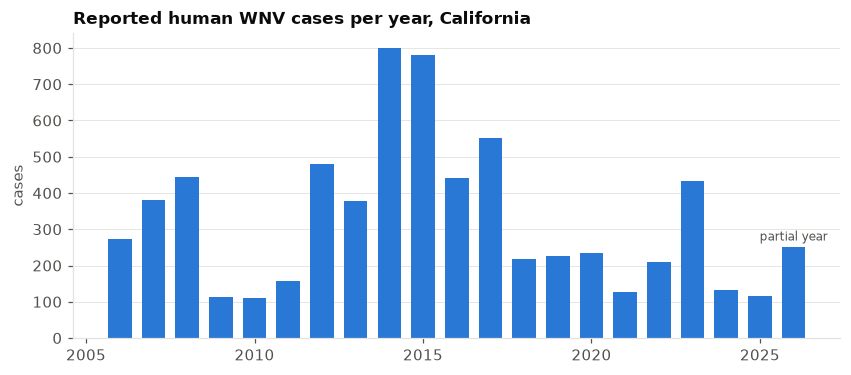

In [9]:
annual = wnv_raw.groupby("Year")[case_col].sum()
fig, ax = plt.subplots()
ax.bar(annual.index, annual.values, color=BLUE, width=0.7)
ax.set_title("Reported human WNV cases per year, California")
ax.set_ylabel("cases")
ax.grid(axis="x", visible=False)
latest = annual.index.max()
ax.annotate("partial year", (latest, annual[latest]), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=8, color=INK2)
plt.show()

### Nuances found in the raw file

**(a) Week 53 in years that have no week 53.** If `Week` were a true MMWR week, it could only be 53
in 53-week years. These rows can't be placed on a real week. The pipeline sets them aside in
`data/processed/wnv_unmatched_rows.csv` instead of dropping them silently (open question **A1**).

In [10]:
wnv_raw["real_weeks"] = wnv_raw.Year.map(lambda y: Year(int(y)).totalweeks())
impossible = wnv_raw[wnv_raw.Week > wnv_raw.real_weeks]
print(f"{len(impossible)} rows / {impossible[case_col].sum()} cases sit in a week that doesn't exist:")
impossible.groupby("Year")[case_col].agg(rows="size", cases="sum")

38 rows / 91 cases sit in a week that doesn't exist:


,rows,cases
Year,,
2010,4,5
2012,2,3
2013,4,4
2017,11,52
2018,10,14
2019,7,13


**(b) Year-end spikes.** Some years have a large share of their cases in week 52 (or 53). That
looks like catch-up reporting of earlier cases, not December transmission. Those cases will be
paired with December weather unless something is done about them (open questions **A2**, **B2**).

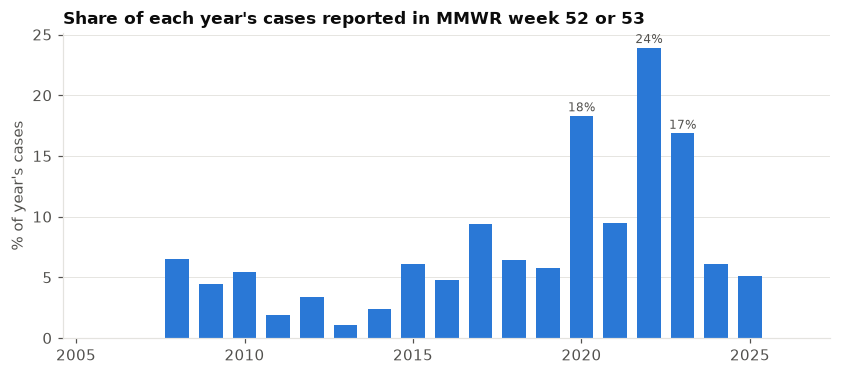

In [11]:
yearend = (wnv_raw[wnv_raw.Week >= 52].groupby("Year")[case_col].sum()
           .reindex(annual.index, fill_value=0) / annual * 100)
fig, ax = plt.subplots()
ax.bar(yearend.index, yearend.values, color=BLUE, width=0.7)
ax.set_title("Share of each year's cases reported in MMWR week 52 or 53")
ax.set_ylabel("% of year's cases")
ax.grid(axis="x", visible=False)
for y, v in yearend.items():
    if v >= 10:
        ax.annotate(f"{v:.0f}%", (y, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=INK2)
plt.show()

**(c) Batchy weekly counts, early-season rows and a duplicate.** Statewide weekly totals jump in a
way that looks like batch reporting (**A2b**). Some cases appear in late winter or spring, long
before the season (**A3**). And one county-week appears twice. The pipeline **sums** duplicate
rows, but only CDPH can say whether that is two cases or one repeated row (**A2c**).

In [12]:
dupes = wnv_raw[wnv_raw.duplicated(["Year", "Week", "County"], keep=False)]
print("Duplicated county-weeks:\n", dupes.drop(columns="real_weeks").to_string(index=False))

early = wnv_raw[wnv_raw.Week <= 17].drop(columns="real_weeks")
print(f"\nRows in MMWR weeks 1-17 (before the usual season): {len(early)}")
print(early.sort_values(["Year", "Week"]).to_string(index=False))

Duplicated county-weeks:
  Year  Week      County  Reported Positive Cases
 2021    52 Santa Clara                        1
 2021    52 Santa Clara                        1

Rows in MMWR weeks 1-17 (before the usual season): 3
 Year  Week     County  Reported Positive Cases
 2007    16       Kern                        1
 2013     9 Sacramento                        1
 2017    17      Kings                        1


In [13]:
statewide = wnv_raw.groupby(["Year", "Week"])[case_col].sum()
print("Statewide cases, 2020 weeks 35-42:", statewide.loc[2020].loc[35:42].to_dict())

Statewide cases, 2020 weeks 35-42: {35: 8, 36: 10, 37: 2, 38: 12, 39: 32, 40: 3, 41: 21, 42: 9}


**(d) The latest week.** The file's last week is CDPH's most recent report. Weeks after it aren't
known to be zero, so the dataset ends there (`bd.latest_wnv_week`, which skips impossible weeks like
week 53 of a 52-week year). Recent weeks keep gaining late reports for some time (**A6**, **B1**).

In [14]:
wnv = bd.load_wnv(RAW / "wnv_human_cases.csv")
last_week = bd.latest_wnv_week(wnv)
print(f"Latest real week in the CDPH file: MMWR {last_week.year} week {last_week.week} "
      f"(starts {last_week.startdate()})")

Latest real week in the CDPH file: MMWR 2026 week 39 (starts 2026-09-27)


**What these counts can and can't tell you**

* **Week reported, not week of onset.** Report trails illness onset by about 5 weeks on average,
  and the delay varies. Onset trails the infectious bite by 2–14 days. So same-week weather is
  the wrong comparison, which is why the dataset has lagged weather columns.
* **County of residence, not county of exposure.** People can be bitten where they work or travel.
* **Small counts.** Most county-weeks are 0, and a single case in a small county gives a large
  weekly incidence.

## 3. Temperature and precipitation (NOAA nClimGrid-Daily)

### Where it lives
[nClimGrid-Daily](https://www.ncei.noaa.gov/products/land-based-station/nclimgrid-daily) is a NOAA
NCEI gridded (~5 km) daily dataset for the contiguous US, interpolated from GHCN-Daily weather
stations, from 1951 on. NCEI also publishes **area averages** of the grid for every US county.
Those are what the pipeline uses. They sit in NOAA's public AWS bucket:

```
https://noaa-nclimgrid-daily-pds.s3.amazonaws.com/access/averages/YYYY/{var}-YYYYMM-cty-{scaled|prelim}.csv
```

* One file per **variable × month**, covering *every county in the US*.
* `scaled` = final data; `prelim` = preliminary recent months, revised until NOAA finalises them.
* Variables: `tmax`, `tmin`, `tavg` (°C), `prcp` (mm).

(The EpiNOAA parquet copies in the same bucket were used at first, but they stopped updating in
February 2026, so the pipeline reads NOAA's own files.)

### Native format
Each file has **no header**: region type, region code, region name, year, month, element, then
**31 day columns**. Days that don't exist (Feb 30) or haven't been processed yet are `-999.99`.
Region codes use **NCEI state numbers**: California is `04`, not FIPS `06`.

In [15]:
sample_url = month_url("tmax", 2020, 7, "scaled")
FALLBACK = "\n".join([
    "cty,01001,AL: Autauga,2020,07,TMAX," + ",".join(["  33.00"] * 31),
    "cty,04029,CA: Kern County,2020,07,TMAX," + ",".join([f"{35 + d / 10:9.2f}" for d in range(31)]),
    "cty,04001,CA: Alameda County,2020,07,TMAX," + ",".join(["  30.56"] * 31),
])
noaa_text, noaa_from = FALLBACK, "stored example (offline)"
if FETCH_NATIVE:
    try:
        noaa_text, noaa_from = get(sample_url, timeout=60).text, sample_url
    except Exception as e:
        print("Live fetch failed, using stored example:", e)

lines = noaa_text.splitlines()
print(f"Source: {noaa_from}\n{len(lines):,} lines (all US counties)\n")
print("First line:\n ", lines[0][:150], "...")
ca = [l for l in lines if l.split(",")[1].strip().startswith("04")]
print(f"\nCalifornia lines (code 04xxx): {len(ca)}\n ", ca[0][:150], "...")

Source: https://noaa-nclimgrid-daily-pds.s3.amazonaws.com/access/averages/2020/tmax-202007-cty-scaled.csv
3,107 lines (all US counties)

First line:
  cty,01001,AL: Autauga,2020,07,TMAX,    32.17,    30.94,    32.00,    33.47,    32.86,    32.84,    31.74,    31.19,    31.07,    32.15,    34.04,    3 ...

California lines (code 04xxx): 58
  cty,04001,CA: Alameda County,2020,07,TMAX,    30.56,    27.59,    25.60,    28.00,    31.94,    30.46,    27.19,    28.92,    30.56,    31.70,    32.7 ...


### How `download_weather.py` fetches and cleans it
For each month from 2005 to the current month:

1. Try the `scaled` (final) files for all four variables. If any is missing (403/404), try the
   `prelim` set. If neither exists, the month isn't published yet and is skipped.
2. `parse_month` cleans each file:
   * names the 37 columns, keeps only rows whose code starts with `04` (California);
   * reshapes the 31 day columns into one row per day, and drops impossible dates
     (Feb 30, Apr 31…);
   * turns `-999.99` into a blank (NaN);
   * builds `fips` as `06` + the last three digits of the code;
   * strips `"CA: "` and `" County"` from the name.
3. Joins the four variables and caches the month as `data/raw/nclimgrid/YYYYMM_{scaled|prelim}.csv`.
   On later runs, `scaled` months are never refetched, but `prelim` months are, until NOAA
   finalises them.
4. Combines all cached months into `nclimgrid_ca_county_daily.csv`, and drops days where *all four*
   variables are blank (days NOAA hasn't processed yet).

Here is `parse_month` applied to the sample above:

In [42]:
parse_month(noaa_text, "tmax").query("county in ['Kern']").head(10)

,date,county,fips,tmax
14,2020-07-01,Kern,06029,32.20
72,2020-07-02,Kern,06029,32.43
130,2020-07-03,Kern,06029,32.72
188,2020-07-04,Kern,06029,33.47
246,2020-07-05,Kern,06029,35.25
304,2020-07-06,Kern,06029,35.91
362,2020-07-07,Kern,06029,35.33
420,2020-07-08,Kern,06029,34.04
478,2020-07-09,Kern,06029,34.34
536,2020-07-10,Kern,06029,36.15


In [17]:
cache = sorted((RAW / "nclimgrid").glob("*.csv"))
status = pd.Series([f.stem.split("_")[1] for f in cache]).value_counts()
print(f"Cached months: {len(cache)}  {status.to_dict()}")
print("Preliminary months (will be refetched):", [f.name for f in cache if "prelim" in f.name])

Cached months: 261  {'scaled': 260, 'prelim': 1}
Preliminary months (will be refetched): ['202609_prelim.csv']


In [18]:
daily = pd.read_csv(RAW / "nclimgrid_ca_county_daily.csv", dtype={"fips": str}, parse_dates=["date"])
print(f"{len(daily):,} county-days, {daily.county.nunique()} counties, "
      f"{daily.date.min():%Y-%m-%d} to {daily.date.max():%Y-%m-%d}")
print("Blank values per variable:", daily[config.WEATHER_VARS].isna().sum().to_dict())
daily[config.WEATHER_VARS].describe().round(2)

460,636 county-days, 58 counties, 2005-01-01 to 2026-09-29
Blank values per variable: {'tmax': 0, 'tmin': 0, 'tavg': 0, 'prcp': 0}


,tmax,tmin,tavg,prcp
count,460636.00,460636.00,460636.00,460636.00
mean,21.56,7.87,14.72,1.82
std,8.86,6.50,7.52,6.44
min,-12.45,-24.78,-17.02,0.00
25%,14.83,3.46,9.30,0.00
50%,21.33,7.88,14.47,0.00
75%,28.51,12.38,20.32,0.05
max,48.57,32.76,39.92,157.59


### How it becomes weekly (`bd.weekly_weather`)
Each day gets its MMWR year/week. Then, per county-week:

| Output | Rule |
|---|---|
| `tmax`, `tmin`, `tavg` | mean of the daily values |
| `prcp_total` | **sum** of daily precipitation. Blank (not 0) if the week has no precipitation values at all |
| `n_days` | number of days with weather. Less than 7 only at the very end of the series, where NOAA's latest month is incomplete |

A week missing only *some* days still sums the days present, which undercounts precipitation. This
only happens in the final, partial week (open question **B8**). A check for one Kern week:

In [19]:
kern_daily = daily[daily.county == "Kern"]
kern_weekly = bd.weekly_weather(kern_daily)
wk = Week(2020, 28)
days = kern_daily[kern_daily.date.between(pd.Timestamp(wk.startdate()), pd.Timestamp(wk.enddate()))]
print(f"Kern, MMWR 2020 week 28 ({wk.startdate()} to {wk.enddate()}): {len(days)} days")
print(f"  by hand: tmax mean {days.tmax.mean():.2f} deg C, prcp sum {days.prcp.sum():.2f} mm")
kern_weekly.query("mmwr_year == 2020 and mmwr_week == 28")

Kern, MMWR 2020 week 28 (2020-07-05 to 2020-07-11): 7 days
  by hand: tmax mean 35.55 deg C, prcp sum 0.00 mm


,county,mmwr_year,mmwr_week,n_days,tmax,tmin,tavg,prcp_total
810,Kern,2020,28,7,35.547143,18.29,26.917143,0.0


**Things to know about the NOAA data**

* **Area averages.** A county value averages the whole county's area. In big, mixed counties
  (San Bernardino, Kern, Riverside, Inyo) that blends desert, mountains and valley floor, while
  people and cases are mostly in the valleys (**B6**).
* **Interpolated, not measured.** Values come from gridding station data, so sparse-station areas
  (mountains, remote desert) are less certain.
* **Preliminary months.** The newest months are `prelim` and will change (**B9**).

## 4. Humidity and vapor pressure deficit (gridMET)

### Where it lives
[gridMET](https://www.climatologylab.org/gridmet.html) (Climatology Lab, University of California
Merced) is a daily **1/24° (~4 km) grid** of surface weather for the contiguous US, from 1979 to
yesterday. It combines PRISM's spatial detail with NLDAS-2 regional reanalysis. The newest days
are provisional and get replaced.

There are **no county averages** to download, so the pipeline computes them itself. It requests the
grid from gridMET's THREDDS **NetCDF Subset Service** (`config.GRIDMET_NCSS`), one aggregated
file per variable covering 1979 to now:

| Pipeline name | gridMET file / variable | Units | Meaning |
|---|---|---|---|
| `rmax` | `rmax` / `daily_maximum_relative_humidity` | % | highest relative humidity of the day (usually near dawn) |
| `rmin` | `rmin` / `daily_minimum_relative_humidity` | % | lowest relative humidity (usually afternoon) |
| `sph`  | `sph` / `daily_mean_specific_humidity` | kg/kg | mass of water vapor per mass of air: absolute moisture, unlike RH |
| `vpd`  | `vpd` / `daily_mean_vapor_pressure_deficit` | kPa | how far the air is from saturation (dryness). Higher = drier air |

### Native format
The server returns **NetCDF**: a 3-D array (`day × lat × lon`) cut to the requested bounding box
and dates. Cells outside the land mask (ocean) are blank. Here is a one-day request for
California, built the same way as `download_gridmet.fetch_var`:

In [20]:
counties = gpd.read_file(RAW / "ca_counties.gpkg")
west, south, east, north = counties.total_bounds
bounds = dict(west=west - 0.05, south=south - 0.05, east=east + 0.05, north=north + 0.05)
SAMPLE_DAY = "2021-07-15"

grid_ds = None
if FETCH_NATIVE:
    try:
        r = get(f"{config.GRIDMET_NCSS}/agg_met_rmax_1979_CurrentYear_CONUS.nc", timeout=120, params={
            "var": config.GRIDMET_NAMES["rmax"],
            **{k: f"{v:.4f}" for k, v in bounds.items()},
            "disableProjSubset": "on", "horizStride": 1, "timeStride": 1,
            "time_start": f"{SAMPLE_DAY}T00:00:00Z", "time_end": f"{SAMPLE_DAY}T00:00:00Z",
            "addLatLon": "true", "accept": "netcdf",
        })
        fd, path = tempfile.mkstemp(suffix=".nc")
        with os.fdopen(fd, "wb") as f:
            f.write(r.content)
        with xr.open_dataset(path, engine="netcdf4") as opened:
            grid_ds = opened.load()
        os.remove(path)
        print(f"Request: {r.url[:120]}...\nResponse: {len(r.content) / 1e6:.1f} MB NetCDF\n")
    except Exception as e:
        print("Live fetch failed; the cells below use a reconstructed 1/24° grid instead:", e)

if grid_ds is not None:
    print(grid_ds)

Request: http://thredds.northwestknowledge.net:8080/thredds/ncss/agg_met_rmax_1979_CurrentYear_CONUS.nc?var=daily_maximum_relativ...
Response: 0.1 MB NetCDF

<xarray.Dataset> Size: 466kB
Dimensions:                          (day: 1, lat: 231, lon: 250)
Coordinates:
  * day                              (day) datetime64[ns] 8B 2021-07-15
  * lat                              (lat) float64 2kB 42.07 42.03 ... 32.48
  * lon                              (lon) float64 2kB -124.5 -124.4 ... -114.1
Data variables:
    daily_maximum_relative_humidity  (day, lat, lon) float64 462kB nan ... 55.6
Attributes: (12/20)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.0
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         32.483333333333334
    geospatial_lat_max:         42.06666666666667
    geospatial_lon_min:         -124.47499996666667
    ...                         ...
    note1:                      The pr

### How `download_gridmet.py` fetches and turns the grid into county averages

1. **County boundaries.** It downloads the Census 2023 cartographic boundary file
   (`cb_2023_us_county_500k`, 1:500,000 scale), keeps California, reprojects to lat/lon (EPSG:4326)
   and caches it as `data/raw/ca_counties.gpkg`.
2. **Request.** For each year × variable, it requests the grid over California's bounding box
   (padded 0.05°) for 1 Jan to 31 Dec (or today). That is about **40 MB per request**, four
   requests per year. The server is called directly, because the PyGridMET library treats any
   blank (ocean) cell as a failed download.
3. **Assign cells to counties** (`cell_county_index`). Each cell goes to the county that contains
   its **center point**. A point exactly on a border keeps one county. Cells outside every county
   (ocean, Nevada, Oregon, Mexico) are ignored. A county containing no cell center would get the
   cell nearest its center; at 4 km this never happens in California.
4. **Average** (`county_means`). It takes a plain `nanmean` over the county's cells for each day:
   no area weighting, and blank ocean cells are skipped.
5. **Cache and combine.** Each year goes to `data/raw/gridmet/YYYY.csv`. The current year is always
   refetched. Then everything is combined into `gridmet_ca_county_daily.csv`.

How many grid cells each county averages over matters. Small coastal counties rest on few cells:

Grid: 231 x 250 = 57,750 cells; 24,012 fall in a CA county
Cells per county: median 234, min 6 (San Francisco), max 2,939 (San Bernardino)


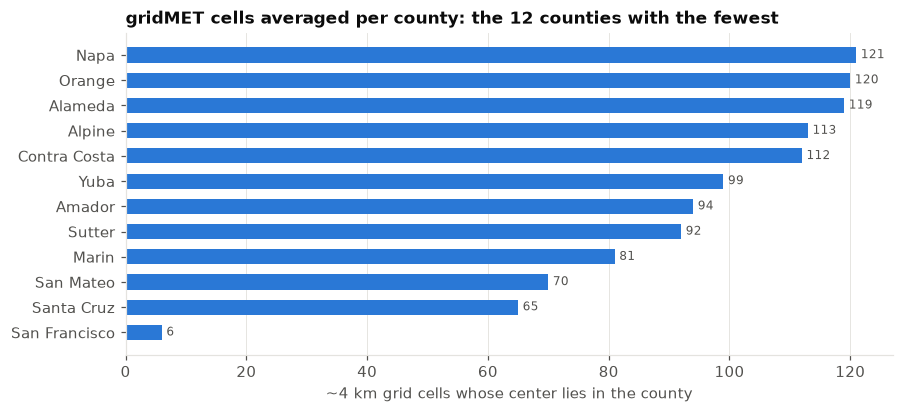

In [21]:
if grid_ds is not None:
    lat, lon = grid_ds["lat"].values, grid_ds["lon"].values
else:  # gridMET's grid spacing is 1/24 degree
    lat = np.arange(bounds["north"], bounds["south"], -1 / 24)
    lon = np.arange(bounds["west"], bounds["east"], 1 / 24)

idx = cell_county_index(lat, lon, counties)
n_cells = (pd.Series(idx[idx >= 0]).value_counts()
           .rename(index=counties["county"]).sort_values())
print(f"Grid: {len(lat)} x {len(lon)} = {idx.size:,} cells; {(idx >= 0).sum():,} fall in a CA county")
print(f"Cells per county: median {n_cells.median():.0f}, min {n_cells.min()} ({n_cells.idxmin()}), "
      f"max {n_cells.max():,} ({n_cells.idxmax()})")

few = n_cells.head(12)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(few.index, few.values, color=BLUE, height=0.6)
for name, v in few.items():
    ax.annotate(str(v), (v, name), xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK2)
ax.set_title("gridMET cells averaged per county: the 12 counties with the fewest")
ax.set_xlabel("~4 km grid cells whose center lies in the county")
ax.grid(axis="y", visible=False)
plt.show()

In [22]:
gm = pd.read_csv(RAW / "gridmet_ca_county_daily.csv", dtype={"fips": str}, parse_dates=["date"])
print(f"{len(gm):,} county-days, {gm.county.nunique()} counties, "
      f"{gm.date.min():%Y-%m-%d} to {gm.date.max():%Y-%m-%d}")
print("Blank values:", gm[bd.GRIDMET_VARS].isna().sum().to_dict())
gm[bd.GRIDMET_VARS].describe().round(4)

460,926 county-days, 58 counties, 2005-01-01 to 2026-10-04
Blank values: {'rmax': 0, 'rmin': 0, 'sph': 0, 'vpd': 0}


,rmax,rmin,sph,vpd
count,460926.0000,460926.0000,460926.0000,460926.0000
mean,74.5798,33.6307,0.0057,1.1770
std,19.0845,17.3619,0.0021,0.8959
min,5.7840,1.0000,0.0004,0.0000
25%,60.4469,20.2830,0.0042,0.4796
50%,77.7948,30.4713,0.0056,0.9273
75%,91.1252,44.5935,0.0071,1.6863
max,100.0000,99.9717,0.0189,6.8115


In [23]:
# Check: averaging the live sample with the pipeline's own function gives the cached values.
if grid_ds is not None:
    ds = grid_ds.rename({config.GRIDMET_NAMES["rmax"]: "rmax", "day": "time"})[["rmax"]]
    live = county_means(ds, counties, ["rmax"]).set_index("county")["rmax"]
    cached = gm[gm.date == SAMPLE_DAY].set_index("county")["rmax"]
    diff = (live - cached).abs()
    print(f"{SAMPLE_DAY}: max |live - cached| rmax over 58 counties = {diff.max():.4f} %")

2021-07-15: max |live - cached| rmax over 58 counties = 0.0001 %


**Weekly** (`bd.weekly_gridmet`): a plain mean of the daily values over each MMWR week, for all
four variables.

**Things to know about gridMET**

* **Computed here, not published.** The county averages are an unweighted mean of cell centers.
  That is fine for big counties. For tiny ones (San Francisco, the smallest county by area, has only
  a handful of cells) the value depends on exactly which cells land inside (**B6**).
* **Area averages again.** As with NOAA, a county mean includes uninhabited mountains and desert.
* **NOAA vs gridMET temperature.** gridMET also has temperature, but the pipeline takes temperature
  from NOAA and only humidity/VPD from gridMET. The two products differ slightly.
* **Provisional recent days** are replaced over time (**B9**).
* **Units.** `sph` is kg/kg (typical values ~0.003–0.015). The plotting script converts it to
  g/kg.

## 5. Drought (US Drought Monitor)

### Where it lives
The [US Drought Monitor](https://droughtmonitor.unl.edu/) (National Drought Mitigation Center at
the University of Nebraska–Lincoln, with USDA and NOAA) releases a **weekly map** each Thursday,
showing conditions as of **Tuesday morning**. The map isn't a single measurement: authors blend
precipitation, soil moisture, streamflow, vegetation and other indicators with local expert
reports. It assigns each area one category:

| Category | Meaning |
|---|---|
| None | not abnormally dry |
| D0 | abnormally dry |
| D1 | moderate drought |
| D2 | severe drought |
| D3 | extreme drought |
| D4 | exceptional drought |

The [data services API](https://droughtmonitor.unl.edu/DmData/DataDownload.aspx) turns each map into
**percent of each county's area** in each category (`config.USDM_URL`).

### How `download_drought.py` fetches it
One request per year: `aoi=CA` (returns every California county), `startdate=1/1/YYYY`,
`enddate=12/31/YYYY`, `statisticsType=1` ("traditional"), `Accept: text/csv`.

* An **empty 200** response means no maps yet for that year, and the year is skipped.
* The script checks the required columns before caching to `data/raw/usdm/YYYY.csv`. The current
  year is always refetched.
* It combines the years, drops duplicate `(FIPS, MapDate)` pairs (a map whose valid period spans
  New Year can come back in two years' requests) and writes `usdm_ca_county_weekly.csv`.

### Native format (as cached)

In [24]:
usdm_raw = pd.read_csv(RAW / "usdm_ca_county_weekly.csv", dtype={"FIPS": str, "MapDate": str})
print(f"{len(usdm_raw):,} county-maps, {usdm_raw.FIPS.nunique()} counties, "
      f"maps {usdm_raw.MapDate.min()} to {usdm_raw.MapDate.max()}")
print("Weekdays of MapDate:", pd.to_datetime(usdm_raw.MapDate).dt.day_name().value_counts().to_dict())
usdm_raw.head()

65,888 county-maps, 58 counties, maps 20041228 to 20260929
Weekdays of MapDate: {'Tuesday': 65888}


,MapDate,FIPS,County,State,None,D0,D1,D2,D3,D4,ValidStart,ValidEnd,StatisticFormatID
0,20041228,06001,Alameda County,CA,100.0,0.0,0.0,0.0,0.0,0.0,2004-12-28,2005-01-03,1
1,20050104,06001,Alameda County,CA,100.0,0.0,0.0,0.0,0.0,0.0,2005-01-04,2005-01-10,1
2,20050111,06001,Alameda County,CA,100.0,0.0,0.0,0.0,0.0,0.0,2005-01-11,2005-01-17,1
3,20050118,06001,Alameda County,CA,100.0,0.0,0.0,0.0,0.0,0.0,2005-01-18,2005-01-24,1
4,20050125,06001,Alameda County,CA,100.0,0.0,0.0,0.0,0.0,0.0,2005-01-25,2005-01-31,1


**The values are cumulative.** With `statisticsType=1`, `D1` means "percent of area in D1 *or
worse*", so the columns never increase from D0 to D4 and a row adds up to more than 100. `None` +
`D0` = 100. `ValidStart`–`ValidEnd` is the Tuesday–Monday week the map stands for.

Example: Kern County at the peak of the 2021 drought.

In [25]:
kern_2021 = usdm_raw.query("County == 'Kern County' and MapDate == '20210727'")
kern_2021[["MapDate", "County", "None", "D0", "D1", "D2", "D3", "D4", "ValidStart", "ValidEnd"]]

,MapDate,County,None,D0,D1,D2,D3,D4,ValidStart,ValidEnd
16769,20210727,Kern County,0.0,100.0,100.0,100.0,100.0,89.41,2021-07-27,2021-08-02


### How it becomes weekly (`bd.weekly_drought`)

1. **Detect the form row by row.** A row is *categorical* if None + D0…D4 ≈ 100. Otherwise it is
   *cumulative* (with a warning if it's neither). The real API always returns cumulative values.
   The check exists so a format change can't silently corrupt the numbers.
2. **Exact percentages:** `usdm_dK` = cumulative DK − cumulative D(K+1), e.g. % in exactly D3 =
   D3 − D4.
3. `usdm_d1plus` = cumulative D1 = % of the county **in drought** (D1 or worse).
4. `usdm_dsci` = **Drought Severity and Coverage Index** = cumulative D0 + D1 + D2 + D3 + D4, from 0
   (no dryness anywhere) to 500 (the whole county in D4).
5. **Timing.** Each map is assigned to the MMWR week containing its `MapDate` (a Tuesday). Every
   Sunday–Saturday week contains exactly one Tuesday, so each week gets exactly one map.

In [26]:
bd.weekly_drought(kern_2021)

,county,usdm_d0,usdm_d1,usdm_d2,usdm_d3,usdm_d4,usdm_d1plus,usdm_dsci,mmwr_year,mmwr_week
16769,Kern,0.0,0.0,0.0,10.59,89.41,100.0,489.41,2021,30


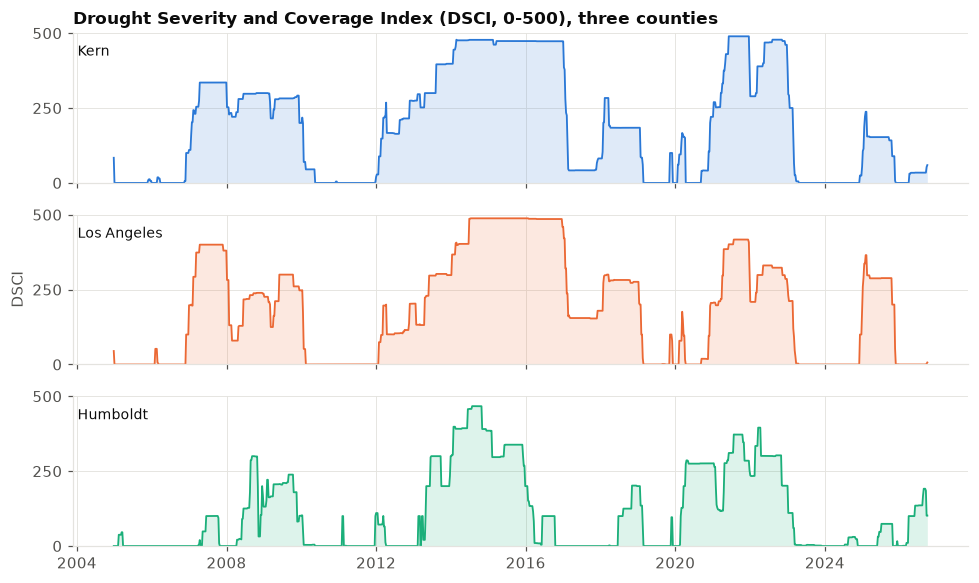

In [27]:
drought_w = bd.weekly_drought(usdm_raw)
drought_w["week_start"] = [bd.week_start(y, w) for y, w in zip(drought_w.mmwr_year, drought_w.mmwr_week)]
fig, axes = plt.subplots(3, 1, figsize=(9, 5.4), sharex=True, sharey=True)
for ax, (name, color) in zip(axes, [("Kern", BLUE), ("Los Angeles", ORANGE), ("Humboldt", AQUA)]):
    s = drought_w[drought_w.county == name].sort_values("week_start")
    ax.fill_between(s.week_start, s.usdm_dsci, color=color, alpha=0.15, linewidth=0)
    ax.plot(s.week_start, s.usdm_dsci, color=color, linewidth=1.2)
    ax.text(0.005, 0.92, name, transform=ax.transAxes, va="top", fontsize=9, color=INK)
    ax.set_ylim(0, 500)
    ax.set_yticks([0, 250, 500])
axes[0].set_title("Drought Severity and Coverage Index (DSCI, 0-500), three counties")
axes[1].set_ylabel("DSCI")
plt.tight_layout()
plt.show()

**Things to know about the Drought Monitor**

* **One snapshot per week.** The value for an MMWR week is that week's Tuesday map. A map partly
  reflects conditions before that week, so using the *previous* week's map would guarantee drought
  comes before the week's cases (**B10**). With the lag columns, this matters little.
* **A judged product.** Categories are set by authors, so they change in steps and can be revised
  in methodology over time. They are not a continuous measurement.
* **Area-based.** The percentages cover land area, not where people live.
* **Long memory.** Drought builds over months. The 1–8-week lags may be too short to capture its
  effect on mosquitoes and birds (**B3**).

## 6. Population (US Census Bureau)

### Where it lives
The Census Bureau's Population Estimates Program publishes **county total population as of July 1**
of each year. No single file covers 2000 to now, so the pipeline stitches three together
(`config.CENSUS_POP_URLS`):

| File | Years | Series | Based on |
|---|---|---|---|
| `co-est00int-tot.csv` | 2000–2010 | **intercensal** (revised to agree with the 2000 and 2010 censuses) | 2000 & 2010 census |
| `co-est2020-alldata.csv` | 2010–2020 | **Vintage 2020 postcensal** | 2010 census |
| `co-est2025-alldata.csv` | 2020–2025 | **Vintage 2025 postcensal** | 2020 census |

The 2010–2020 *intercensal* series would be better, but Census publishes it for counties only broken
down by age, sex and race, not as totals (**B7**).

### Native format
Each file is **wide**: one row per state and per county, with `SUMLEV` (40 = state, 50 = county),
`STATE`/`COUNTY` FIPS parts, `CTYNAME` and one `POPESTIMATEYYYY` column per year, among many
other components (births, deaths, migration). The files are Latin-1 encoded.

In [28]:
census_native = None
if FETCH_NATIVE:
    try:
        r = get(config.CENSUS_POP_URLS[-1], timeout=120)
        census_native = pd.read_csv(io.BytesIO(r.content), encoding="latin-1", dtype=str)
    except Exception as e:
        print("Live fetch failed:", e)
if census_native is not None:
    print(f"{config.CENSUS_POP_URLS[-1].rsplit('/', 1)[-1]}: {census_native.shape[0]:,} rows "
          f"x {census_native.shape[1]} columns")
    print("POPESTIMATE columns:", [c for c in census_native.columns if c.startswith("POPESTIMATE")])
    cols = ["SUMLEV", "STATE", "COUNTY", "STNAME", "CTYNAME", "POPESTIMATE2020", "POPESTIMATE2025"]
    display(census_native.loc[census_native.STATE == "06", cols].head(4))

co-est2025-alldata.csv: 3,195 rows x 99 columns
POPESTIMATE columns: ['POPESTIMATE2020', 'POPESTIMATE2021', 'POPESTIMATE2022', 'POPESTIMATE2023', 'POPESTIMATE2024', 'POPESTIMATE2025']


,SUMLEV,STATE,COUNTY,STNAME,CTYNAME,POPESTIMATE2020,POPESTIMATE2025
191,040,06,000,California,California,39527808,39355309
192,050,06,001,California,Alameda County,1680489,1636630
193,050,06,003,California,Alpine County,1180,1043
194,050,06,005,California,Amador County,40567,41876


### How `download_population.py` cleans it
* `tidy_census`: keeps `SUMLEV == 50` (counties) in state `06`, reshapes `POPESTIMATEYYYY` into
  long rows (county, fips, year, population), strips `" County"` from names and records the source
  file as `vintage`.
* `combine`: stacks the three files oldest first. Where years overlap (2010, 2020), the **newest
  vintage wins**.

In [29]:
pop = pd.read_csv(RAW / "ca_county_population.csv", dtype={"fips": str})
print(f"{pop.county.nunique()} counties, {pop.year.min()}-{pop.year.max()}")
pop.groupby("vintage").year.agg(["min", "max", "nunique"]).sort_values("min")

58 counties, 2000-2025


,min,max,nunique
vintage,,,
co-est00int-tot,2000,2009,10
co-est2020-alldata,2010,2019,10
co-est2025-alldata,2020,2025,6


**The 2019 → 2020 step.** 2019 comes from the 2010-census-based series and 2020 from the
2020-census-based one. Where the 2010-based estimates had drifted, there is a jump between those
two years. For most counties it is under 1%, but some small counties jump a lot:

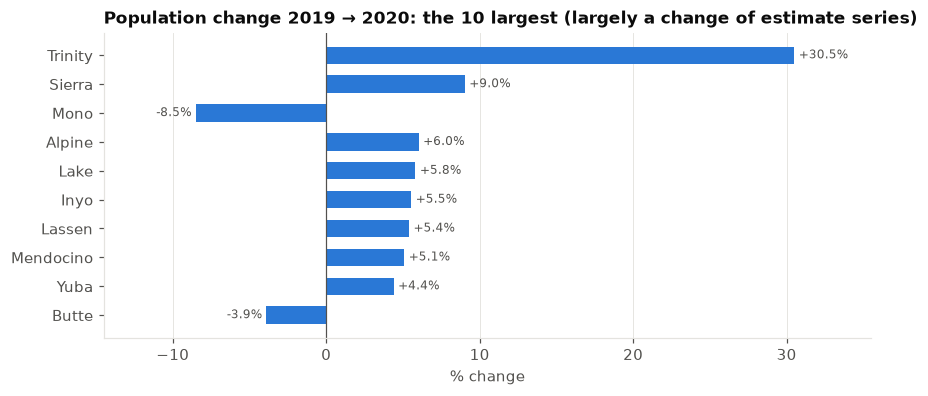

Median absolute change across 58 counties: 1.20%


In [30]:
wide = pop.pivot(index="county", columns="year", values="population")
step = ((wide[2020] / wide[2019] - 1) * 100).sort_values(key=abs, ascending=False)
top = step.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.axvline(0, color=INK2, linewidth=0.8)
for name, v in top.items():
    ax.annotate(f"{v:+.1f}%", (v, name), xytext=(3 if v >= 0 else -3, 0), textcoords="offset points",
                va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
ax.set_xlim(top.min() - 6, top.max() + 5)
ax.set_title("Population change 2019 → 2020: the 10 largest (largely a change of estimate series)")
ax.set_xlabel("% change")
ax.grid(axis="y", visible=False)
plt.show()
print(f"Median absolute change across 58 counties: {step.abs().median():.2f}%")

### How it enters the dataset (`bd.population_by_year`)
* Each county-week gets the July 1 estimate **for its MMWR year**. Population changes in a step each
  January, with no interpolation between estimates (**B7**).
* Years after the latest estimate (2025) **reuse it**, flagged `pop_carried_forward = True`.
* Derived columns: `incidence_per_100k = wnv_cases / population × 100,000` and
  `log_pop = log(population)` (the offset for a count model).

In [31]:
bd.population_by_year(pop, pd.Series([2024, 2025, 2026])).query("county == 'Kern'")

,county,mmwr_year,population,pop_carried_forward
42,Kern,2024,924648,False
43,Kern,2025,927068,False
44,Kern,2026,927068,True


## 7. Joining everything: `build_dataset.py`

`build_dataset.main` reads the five raw files and calls `build()`. gridMET, drought and population
are optional: if a file is missing, its columns are left out and a message says so. The steps, in
order:

1. **Weekly weather** (`weekly_weather`): NOAA daily → county × MMWR week (section 3).
2. **A complete grid of rows** (`week_grid`): every county × every MMWR week from the first weather
   week (2005) to the last week of the period. A week missing from a source then shows up as
   **blank cells, not a missing row**. `fips` is filled from `CA_COUNTIES`. Weeks with no weather get
   `n_days = 0`.
3. **WNV cases**: normalise county names, **sum duplicate rows**, left-join on
   (county, MMWR year, week), and fill county-weeks absent from the CDPH file with **0**. WNV rows
   that match no row in the grid (impossible week 53s, unknown county names) are collected as
   `unmatched`.
4. **gridMET** weekly means and **Drought Monitor** weekly values are left-joined on the same keys.
   `build` raises an error if any county-week now appears more than once.
5. **Lags** (`add_lags`): for each of `tavg, tmax, tmin, prcp_total, rmax, rmin, sph, vpd, usdm_dsci`
   and k = 1, 2, 3, 4, 6, 8, `<var>_lag<k>` is the value from the row whose `week_start` is exactly
   7·k days earlier, for the same county. Matching **by date** (not by shifting rows) means a gap
   gives a blank lag instead of misaligning everything after it.
6. **Trim to the analysis period**: MMWR 2006 week 1 through the latest real CDPH week. This
   happens **after** the lags, so early-2006 rows have lags drawn from late 2005.
7. **Population** for the MMWR year, then `incidence_per_100k` and `log_pop`.

Outputs: `data/processed/ca_wnv_weather_weekly.csv`, plus `data/processed/wnv_unmatched_rows.csv`
if any WNV rows didn't match.

### Rebuild from the raw files and compare with the saved output
This runs the real `build()` on all the raw data (a few seconds).

In [32]:
gridmet_raw = pd.read_csv(RAW / "gridmet_ca_county_daily.csv", dtype={"fips": str})
daily_raw = pd.read_csv(RAW / "nclimgrid_ca_county_daily.csv", dtype={"fips": str})
period = (Week(START_YEAR, 1), bd.latest_wnv_week(wnv))

t0 = time.time()
dataset, unmatched = bd.build(daily_raw, wnv, gridmet_raw, usdm_raw, pop, period)
print(f"build() took {time.time() - t0:.0f} s -> {dataset.shape[0]:,} rows x {dataset.shape[1]} columns")

saved = pd.read_csv(PROCESSED / "ca_wnv_weather_weekly.csv", dtype={"fips": str}, parse_dates=["week_start"])
try:
    pd.testing.assert_frame_equal(dataset.reset_index(drop=True), saved, check_dtype=False, rtol=1e-9)
    print("The rebuilt dataset matches data/processed/ca_wnv_weather_weekly.csv exactly.")
except AssertionError as e:
    print("Rebuilt dataset differs from the saved file (raw files may have been updated since):\n", str(e)[:600])

build() took 3 s -> 62,814 rows x 80 columns
The rebuilt dataset matches data/processed/ca_wnv_weather_weekly.csv exactly.


### Every case is accounted for
Cases in the CDPH file = cases in the dataset + cases set aside as unmatched.

In [33]:
raw_total = wnv_raw[case_col].sum()
out_total = dataset.wnv_cases.sum()
print(f"CDPH file: {raw_total:,} cases  =  dataset: {out_total:,}  +  unmatched: {unmatched.wnv_cases.sum():,}")
assert raw_total == out_total + unmatched.wnv_cases.sum()
print("\nUnmatched rows (saved to data/processed/wnv_unmatched_rows.csv):")
print(unmatched.groupby("mmwr_year").wnv_cases.agg(rows="size", cases="sum").to_string())

CDPH file: 6,861 cases  =  dataset: 6,770  +  unmatched: 91

Unmatched rows (saved to data/processed/wnv_unmatched_rows.csv):
           rows  cases
mmwr_year             
2010          4      5
2012          2      3
2013          4      4
2017         11     52
2018         10     14
2019          7     13


### What the lag columns look like
Each lag column holds the value from k weeks earlier for the same county. Reading diagonally shows
the shift: this week's `tavg` becomes next week's `tavg_lag1`.

In [34]:
cols = ["county", "mmwr_year", "mmwr_week", "week_start", "tavg", "tavg_lag1", "tavg_lag2", "tavg_lag8"]
lag_view = dataset.loc[dataset.county == "Kern", cols].query("mmwr_year == 2006").head(6)
lag_view.round({c: 2 for c in cols[4:]})

,county,mmwr_year,mmwr_week,week_start,tavg,tavg_lag1,tavg_lag2,tavg_lag8
15162,Kern,2006,1,2006-01-01,9.37,10.77,11.68,13.38
15163,Kern,2006,2,2006-01-08,8.98,9.37,10.77,13.66
15164,Kern,2006,3,2006-01-15,5.80,8.98,9.37,13.76
15165,Kern,2006,4,2006-01-22,7.30,5.80,8.98,9.23
15166,Kern,2006,5,2006-01-29,10.31,7.30,5.80,6.41
15167,Kern,2006,6,2006-02-05,12.33,10.31,7.30,7.71


In [35]:
print("The first week of 2006 has lags reaching back into 2005 (no blanks):")
first = dataset[(dataset.mmwr_year == 2006) & (dataset.mmwr_week == 1)]
print(first.filter(like="_lag8").isna().sum().to_string())

The first week of 2006 has lags reaching back into 2005 (no blanks):
tavg_lag8          0
tmax_lag8          0
tmin_lag8          0
prcp_total_lag8    0
rmax_lag8          0
rmin_lag8          0
sph_lag8           0
vpd_lag8           0
usdm_dsci_lag8     0


## 8. The final dataset

`data/processed/ca_wnv_weather_weekly.csv`: **one row per county per MMWR week**, 58 counties, from
MMWR 2006 week 1 to the latest CDPH week.

In [36]:
df = dataset
print(f"{len(df):,} rows = {df.county.nunique()} counties x {df.groupby('county').size().iloc[0]} weeks")
print(f"Weeks: {df.week_start.min():%Y-%m-%d} to {df.week_start.max():%Y-%m-%d}")
print(f"Unique county-weeks: {not df.duplicated(['county', 'mmwr_year', 'mmwr_week']).any()}")
print(f"Columns: {df.shape[1]} ({df.filter(like='_lag').shape[1]} of them lags)")

62,814 rows = 58 counties x 1083 weeks
Weeks: 2006-01-01 to 2026-09-27
Unique county-weeks: True
Columns: 80 (54 of them lags)


### Column dictionary

| Column | Source | Meaning |
|---|---|---|
| `county`, `fips` | `config.CA_COUNTIES` | County name and 5-digit FIPS |
| `mmwr_year`, `mmwr_week`, `week_start` | `epiweeks` | MMWR week; `week_start` is its Sunday |
| `n_days` | NOAA | Days of weather in the week (7 except at the end of the series) |
| `tmax`, `tmin`, `tavg` | NOAA | Weekly mean of daily max / min / average temperature (°C) |
| `prcp_total` | NOAA | Weekly total precipitation (mm) |
| `wnv_cases` | CDPH | Human WNV disease cases reported that week (0 if the county-week isn't in the CDPH file) |
| `rmax`, `rmin` | gridMET | Weekly mean of daily max / min relative humidity (%) |
| `sph` | gridMET | Weekly mean specific humidity (kg/kg) |
| `vpd` | gridMET | Weekly mean vapor pressure deficit (kPa) |
| `usdm_d0` … `usdm_d4` | Drought Monitor | % of county area in exactly that category |
| `usdm_d1plus` | Drought Monitor | % of county area in drought (D1 or worse) |
| `usdm_dsci` | Drought Monitor | Drought Severity and Coverage Index, 0–500 |
| `population` | Census | July 1 estimate for the MMWR year |
| `pop_carried_forward` | Census | True when the year is past the latest estimate and it is reused |
| `incidence_per_100k` | derived | `wnv_cases / population × 100,000` |
| `log_pop` | derived | `log(population)`, an offset for count models |
| `<var>_lag<k>` | derived | `<var>` from k weeks earlier (k = 1, 2, 3, 4, 6, 8) |

### Completeness
Blank values in the non-lag columns (in the current build every source covers every county-week),
then the partial final week and the carried-forward population.

In [37]:
base = [c for c in df.columns if "_lag" not in c]
blank = df[base].isna().sum()
blank = blank[blank > 0]
if blank.empty:
    print(f"No blank values in any of the {len(base)} non-lag columns.")
    print(f"Lag columns with blanks: {int((df.filter(like='_lag').isna().sum() > 0).sum())}")
else:
    where = {c: sorted({f"{y}-W{w:02d}" for y, w in df.loc[df[c].isna(), ["mmwr_year", "mmwr_week"]].values})
             for c in blank.index}
    display(pd.DataFrame({"blank rows": blank,
                          "weeks affected": [", ".join(v[:6]) + (" …" if len(v) > 6 else "") for v in where.values()]}))

No blank values in any of the 26 non-lag columns.
Lag columns with blanks: 0


In [38]:
partial = df[df.n_days < 7].groupby(["mmwr_year", "mmwr_week"]).n_days.agg(["min", "max", "size"])
print("Weeks with fewer than 7 days of NOAA weather:\n", partial.to_string())
print("\nYears using carried-forward population:",
      sorted(df.loc[df.pop_carried_forward, "mmwr_year"].unique().tolist()))

Weeks with fewer than 7 days of NOAA weather:
                      min  max  size
mmwr_year mmwr_week                
2026      39           3    3    58

Years using carried-forward population: [2026]


### What the case data look like at county-week resolution

In [39]:
print(f"County-weeks with 0 cases: {(df.wnv_cases == 0).mean():.1%}")
print("Distribution of weekly cases where > 0:", df.loc[df.wnv_cases > 0, "wnv_cases"].describe().round(1).to_dict())

by_county = df.groupby("county").agg(cases=("wnv_cases", "sum"), mean_pop=("population", "mean"))
by_county["cases_per_100k_per_year"] = by_county.cases / by_county.mean_pop * 1e5 / df.mmwr_year.nunique()
print("\nTop 10 counties by total cases:")
by_county.sort_values("cases", ascending=False).head(10).round(2)

County-weeks with 0 cases: 95.7%
Distribution of weekly cases where > 0: {'count': 2684.0, 'mean': 2.5, 'std': 3.6, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 42.0}

Top 10 counties by total cases:


,cases,mean_pop,cases_per_100k_per_year
county,,,
Los Angeles,2016,9877013.36,0.97
Orange,648,3100822.63,1.00
Kern,494,874773.11,2.69
Riverside,395,2338892.15,0.80
Fresno,368,972004.75,1.80
Stanislaus,360,534864.03,3.21
San Bernardino,286,2118634.03,0.64
Butte,275,217513.97,6.02
Sacramento,260,1504302.97,0.82


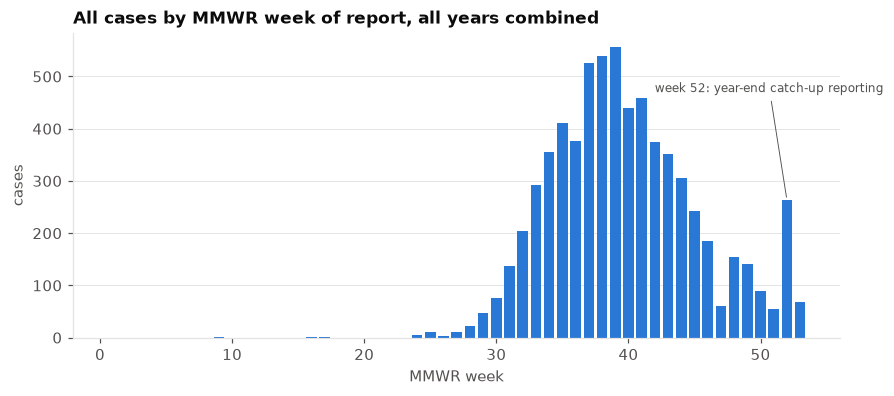

In [40]:
season = df.groupby("mmwr_week").wnv_cases.sum()
fig, ax = plt.subplots()
ax.bar(season.index, season.values, color=BLUE, width=0.8)
ax.set_title("All cases by MMWR week of report, all years combined")
ax.set_xlabel("MMWR week")
ax.set_ylabel("cases")
ax.grid(axis="x", visible=False)
ax.annotate("week 52: year-end catch-up reporting", (52, season.loc[52]), xytext=(42, 470),
            textcoords="data", fontsize=8, color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.6))
plt.show()

## 9. Limitations and open questions

The full lists are in [docs/OPEN_QUESTIONS.md](../docs/OPEN_QUESTIONS.md) (codes A1–B11 below) and
[docs/REVIEW_CHECKLIST.md](../docs/REVIEW_CHECKLIST.md).

### About the case data (the outcome)
| Issue | Effect | Status |
|---|---|---|
| Cases counted by **week reported**, ~5 weeks after onset on average, with variable delay | Same-week weather is the wrong comparison; the timing signal is blurred | Lag columns; onset-week data would be better (A5, B3) |
| **County of residence**, not of exposure | Some cases are assigned to the wrong county's weather | Inherent |
| **Week 53** in years with no week 53 | Can't be placed on a real week | Set aside in `wnv_unmatched_rows.csv` (A1) |
| **Year-end spikes** in week 52/53 (up to ~24% of a year's cases) | Summer infections paired with December weather | Kept as is for now (A2, B2) |
| **Batch reporting**, early-season rows | Week-to-week noise unrelated to transmission | Consider monthly aggregation (A2b, A3, B4) |
| One **duplicated row** | ±1 case | Summed (A2c) |
| **Recent weeks incomplete** | Latest weeks undercount | Period ends at CDPH's last week; how many more weeks to drop is open (A6, B1) |
| **Disease cases only** | Asymptomatic infections (blood donors) excluded | Inherent |
| **Small counts**: ~96% of county-weeks are 0; 8 counties never have a case | Extreme incidence in small counties; zero-heavy outcome | Modelling choice (B5, B11) |

### About the exposures (weather, humidity, drought)
| Issue | Effect | Status |
|---|---|---|
| **County area averages** | Mixes uninhabited mountains/desert with populated valleys | Population weighting possible (B6) |
| **gridMET averages computed here**: unweighted cell centers | Small counties rest on few cells | Area weighting possible (B6) |
| **Preliminary data** (NOAA `prelim`, gridMET provisional) | Latest weeks will be revised | Visible in download log and cache names (B9) |
| **Partial last week** (`n_days < 7`) | Precipitation total undercounted | Open (B8) |
| **Drought map timing**: the Tuesday map of the same week | Drought value isn't strictly before the week | Lags reduce the issue (B10) |
| **Lags only to 8 weeks** | Longer weather/drought effects not captured | Extend lags, rolling means or a distributed lag model (B3) |
| **Different products** for temperature (NOAA) and humidity (gridMET) | Small inconsistencies between them | Inherent |

### About population (the denominator)
| Issue | Effect | Status |
|---|---|---|
| **2019 → 2020 series change** | Step of up to +30% (Trinity) in small counties | Open (B7) |
| **Yearly steps**, no interpolation | Population jumps each January | Open (B7) |
| **2026 reuses 2025** | Slight error in current-year incidence | Flagged by `pop_carried_forward` |

### Not in the dataset
Mosquito infection rates and dead-bird surveillance (VectorSurv), usually the strongest short-term
predictors of human WNV, are not included (A7). Neither are land use, irrigation or socioeconomic
variables.

## 10. Rebuilding from scratch

From the project root, with the `.venv` activated:

```bash
python -m src.download_wnv        # seconds
python -m src.download_weather    # ~1,000 monthly files; a few minutes the first time
python -m src.download_gridmet    # ~35 s per year; cached afterwards
python -m src.download_drought    # under a minute
python -m src.download_population # seconds
python -m src.build_dataset       # writes data/processed/
pytest                            # checks the parsing and join logic
```

Data files aren't committed to git. Rerunning these commands recreates them, but the results
reflect each source *as of the day you download*. Check `data/raw/download_log.csv` to see which
version a given build used.